In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

In [2]:
BASE_DIR = "/data0/hernanqd/plots_code/skagit-met/updating_multi_product_bulk_bias"
INPUT_CSV = os.path.join(BASE_DIR, "outputs/3.75_events_with_prior_counts.csv")
QUICKFLOW_CSV = Path("/data0/hernanqd/plots_code/skagit-met/data/baseflow_separation/usgs_12200500_discharge_with_baseflow.csv")
OUT_DIR = os.path.join(BASE_DIR, "plots")

def load_quickflow_data():
    """Load quickflow (direct_runoff_cms) from baseflow-separated discharge data."""
    print(f"Loading quickflow data from {QUICKFLOW_CSV}...")
    qf_df = pd.read_csv(QUICKFLOW_CSV, parse_dates=['date'])
    print(f"  Loaded {len(qf_df)} days of discharge data")
    return qf_df[['date', 'direct_runoff_cms']].rename(columns={'direct_runoff_cms': 'quickflow_cms'})

In [3]:
print(f"Loading data from {INPUT_CSV}...")
df = pd.read_csv(INPUT_CSV, parse_dates=['date'])

# Load and merge quickflow data
qf_df = load_quickflow_data()
df = pd.merge(df, qf_df, on='date', how='left')
if 'quickflow_cms' in df.columns:
    print(f"  Merged quickflow data for {df['quickflow_cms'].notna().sum()} events")

# Remove rows with missing data
df_clean = df.dropna(subset=['prism_7d_tot', 'quickflow_cms', 'events_in_prior_7days'])

print(f"Total events with complete data: {len(df_clean)}")
print(f"\nData ranges:")
print(f"  7-day antecedent precip (prism_7d_tot) - min: {df_clean['prism_7d_tot'].min():.1f}, "
        f"max: {df_clean['prism_7d_tot'].max():.1f}, "
        f"mean: {df_clean['prism_7d_tot'].mean():.1f}")
print(f"  Quickflow (cms) - min: {df_clean['quickflow_cms'].min():.2f}, "
        f"max: {df_clean['quickflow_cms'].max():.2f}, "
        f"mean: {df_clean['quickflow_cms'].mean():.2f}")
print(f"  Events in prior 7 days - min: {df_clean['events_in_prior_7days'].min():.0f}, "
        f"max: {df_clean['events_in_prior_7days'].max():.0f}, "
        f"mean: {df_clean['events_in_prior_7days'].mean():.1f}")

Loading data from /data0/hernanqd/plots_code/skagit-met/updating_multi_product_bulk_bias/outputs/3.75_events_with_prior_counts.csv...
Loading quickflow data from /data0/hernanqd/plots_code/skagit-met/data/baseflow_separation/usgs_12200500_discharge_with_baseflow.csv...
  Loaded 16802 days of discharge data
  Merged quickflow data for 1109 events
Total events with complete data: 1109

Data ranges:
  7-day antecedent precip (prism_7d_tot) - min: 0.0, max: 381.4, mean: 86.4
  Quickflow (cms) - min: 0.00, max: 3117.91, mean: 291.21
  Events in prior 7 days - min: 0, max: 3, mean: 0.5


In [4]:
df_clean

,date,discharge_cfs,gage_height_ft,ar_scale_47.5N_124.5W,ar_scale_48.0N_124.5W,ar_scale_48.5N_124.5W,ar_scale,prism_3d_tot,prism_3d_max,prism_7d_tot,...,ornl_mean_7d_tot,ornl_mean_7d_max,ornl_median_7d_tot,ornl_median_7d_max,events_in_prior_7days,events_in_prior_30days,non_ar_events_in_prior_7days,non_ar_events_in_prior_30days,days_to_prior_event,quickflow_cms
0,1981-01-10,15600,NaN,0.0,0.0,0.0,0.0,2.044164,1.804440,2.859853,...,79.733953,17.155886,63.285784,15.438743,0,0,0,0,NaN,112.846480
1,1981-01-19,12600,NaN,3.0,2.0,2.0,2.0,10.901503,5.964880,10.921308,...,59.548147,15.487469,40.146504,9.806755,0,1,0,1,9.0,64.738322
2,1981-01-22,14500,NaN,2.0,2.0,1.0,1.0,16.773908,9.149193,27.695216,...,62.970259,15.487469,32.144054,9.806755,1,2,0,1,3.0,125.830932
3,1981-01-28,13600,NaN,0.0,0.0,0.0,0.0,20.631929,17.182711,44.358794,...,55.465197,12.690192,37.697740,10.300223,1,3,0,1,6.0,136.349548
4,1981-02-17,43700,NaN,3.0,3.0,3.0,3.0,132.032945,61.337775,214.498757,...,68.327923,14.470674,62.040271,14.830664,0,3,0,1,20.0,1020.118282
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1104,2024-12-07,14300,14.03,2.0,3.0,3.0,2.0,12.220839,12.059908,12.401685,...,99.250694,19.640696,95.964696,19.051945,0,3,0,1,14.0,122.156551
1105,2024-12-18,28000,18.66,2.0,2.0,2.0,2.0,61.014197,46.741881,91.687790,...,72.966943,15.418537,66.098148,13.404315,0,2,0,1,11.0,471.989926
1106,2024-12-20,23500,17.49,1.0,1.0,1.0,1.0,78.377224,46.741881,121.920241,...,71.599070,15.418537,63.626192,13.404315,1,3,0,1,2.0,332.319581
1107,2024-12-24,22300,17.08,1.0,1.0,1.0,1.0,43.972618,20.309526,127.175319,...,85.826003,21.859554,77.463459,21.947944,2,3,0,0,4.0,270.902988


In [5]:
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from scipy.stats import spearmanr, kruskal

d = df_clean.sort_values("date").reset_index(drop=True)
print(d["days_to_prior_event"].describe())
print(d["days_to_prior_event"].value_counts().sort_index().head(12))

count    1108.000000
mean       14.494585
std        19.786689
min         1.000000
25%         6.000000
50%         7.000000
75%        14.000000
max       186.000000
Name: days_to_prior_event, dtype: float64
days_to_prior_event
1.0      24
2.0      54
3.0      71
4.0      56
5.0      48
6.0     234
7.0      85
8.0      47
9.0      45
10.0     35
11.0     48
12.0     40
Name: count, dtype: int64


In [6]:
g6 = d["days_to_prior_event"] == 6
print(d.loc[g6, "ar_scale"].value_counts(normalize=True).sort_index())
print(d.loc[~g6, "ar_scale"].value_counts(normalize=True).sort_index())
print(d.groupby(g6)["quickflow_cms"].median())

ar_scale
0.0    0.764957
1.0    0.136752
2.0    0.051282
3.0    0.034188
4.0    0.012821
Name: proportion, dtype: float64
ar_scale
0.0    0.185143
1.0    0.420571
2.0    0.244571
3.0    0.116571
4.0    0.027429
5.0    0.005714
Name: proportion, dtype: float64
days_to_prior_event
False    182.208992
True     119.755158
Name: quickflow_cms, dtype: float64


gap_prev_ar
1.0     24
2.0     54
3.0     71
4.0     56
5.0     48
6.0     36
7.0     33
8.0     18
9.0     20
10.0    19
11.0    21
12.0    20
Name: count, dtype: int64
           n      median        mean         p90
gap_bin                                         
1–2       78  373.653017  519.192816  997.936738
3–5      175  270.902988  434.630710  913.121221
6–10     126  209.786380  378.962556  971.079577
11–20    159  181.012459  313.294372  848.503914
>20      229  133.402239  265.890169  711.041017


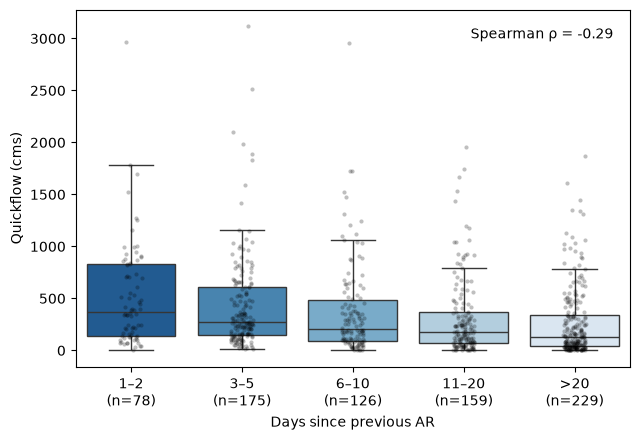

In [7]:
d = df_clean.sort_values("date").reset_index(drop=True)
d["date"] = pd.to_datetime(d["date"])

ar = d[d["ar_scale"] > 0].copy()
ar["gap_prev_ar"] = ar["date"].diff().dt.days      # days since previous AR, ignoring non-AR events
ar = ar.dropna(subset=["gap_prev_ar", "quickflow_cms"])

print(ar["gap_prev_ar"].value_counts().sort_index().head(12))

labels = ["1–2", "3–5", "6–10", "11–20", ">20"]
ar["gap_bin"] = pd.cut(ar["gap_prev_ar"], bins=[0, 2, 5, 10, 20, np.inf], labels=labels)

print(ar.groupby("gap_bin", observed=True)["quickflow_cms"]
        .agg(n="count", median="median", mean="mean", p90=lambda s: s.quantile(0.9)))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.boxplot(data=ar, x="gap_bin", y="quickflow_cms", hue="gap_bin", palette="Blues_r",
            legend=False, showfliers=False, ax=ax)
sns.stripplot(data=ar, x="gap_bin", y="quickflow_cms", color="k", alpha=0.25, size=3, ax=ax)

n = ar["gap_bin"].value_counts().reindex(labels)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels([f"{l}\n(n={n[l]})" for l in labels])
ax.set_xlabel("Days since previous AR")
ax.set_ylabel("Quickflow (cms)")

rho, p = spearmanr(ar["gap_prev_ar"], ar["quickflow_cms"])
ax.text(0.97, 0.95, f"Spearman ρ = {rho:.2f}", transform=ax.transAxes, ha="right", va="top")
plt.tight_layout()
plt.show()

gap_grp  ≤5 d  6–10 d  >10 d
size                        
Small      55      42    159
Medium     99      40    116
Large      99      44    113


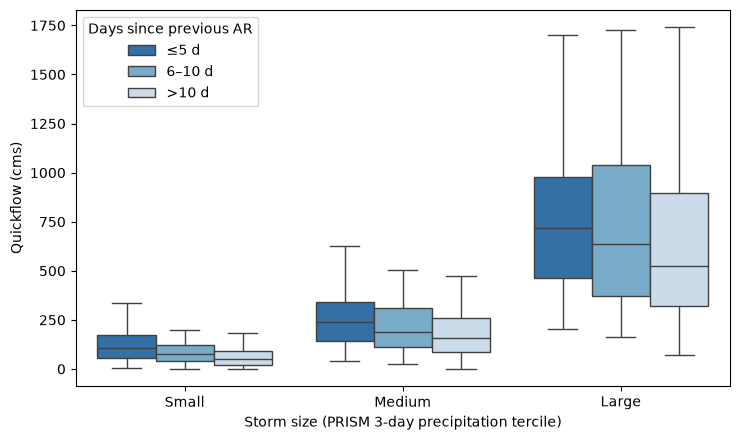

Small: Spearman rho = -0.23, p = 0.000
Medium: Spearman rho = -0.19, p = 0.003
Large: Spearman rho = -0.16, p = 0.012


In [8]:
ar["size"] = pd.qcut(ar["prism_3d_tot"], 3, labels=["Small", "Medium", "Large"])
ar["gap_grp"] = pd.cut(ar["gap_prev_ar"], bins=[0, 5, 10, np.inf], labels=["≤5 d", "6–10 d", ">10 d"])

print(pd.crosstab(ar["size"], ar["gap_grp"]))     # check every cell has enough events

fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.boxplot(data=ar, x="size", y="quickflow_cms", hue="gap_grp",
            palette="Blues_r", showfliers=False, ax=ax)
ax.set_xlabel("Storm size (PRISM 3-day precipitation tercile)")
ax.set_ylabel("Quickflow (cms)")
ax.legend(title="Days since previous AR")
plt.tight_layout()
plt.show()

for s, g in ar.groupby("size", observed=True):
    r, p = spearmanr(g["gap_prev_ar"], g["quickflow_cms"])
    print(f"{s}: Spearman rho = {r:.2f}, p = {p:.3f}")